# Three business questions on the gold layer (epic 5)

Answers three business questions from the gold tables (RF-05,
[ADR 012](../docs/adr/012-gold-aggregations-and-counting-rules.md)): openings per year, UF and
CNAE; active companies by size and region; sectors with the most closed or unfit companies.

**Where the data and the outputs come from.** The lake lives in MinIO inside a GitHub runner
(ADR 006; no real data on the development laptop). The manual
[`Gold analysis`](../.github/workflows/gold-analysis.yml) workflow downloads a release subset,
runs `make bronze`, `make silver` and `make gold` (sum checks against silver),
exports small roll-ups of the three gold tables to `data/*.csv`
(`scripts/gold_export.py`) and executes this notebook on them with `nbconvert`. The executed
notebook and the CSVs are the workflow artifact and are committed as is. They hold aggregates
only (counts by year, UF, CNAE, size, status x sector): no rows, names or CNPJs (RST-01/LGPD).
The first cell prints the reference month, the files loaded and the silver counts.

**Scope: a sample, not the full release.** The default subset is `lookups` + `Empresas1` +
`Estabelecimentos1` of 2026-09. `Estabelecimentos1` (~350 MB zipped) is about **6.5% of the
establishment files by size** (5.38 GB in ten files, of which `Estabelecimentos0` alone is
2.24 GB, [data source](../docs/data-source.md)), and `Empresas1` about 6% of the companies.
**Absolute numbers are therefore partial; only shares, rates and rankings are meaningful**, and
only as far as the files are a fair sample of the release (the source does not document how
records are split across files). Companies are joined to establishments by `cnpj_basico`
within the loaded files only: `silver.without_company` in the first cell counts the loaded
establishments whose company is in another `Empresas` file (they are left out of the size
table, ADR 012). To widen the sample, run the workflow with more files (`files` input); the
runner has ~14 GB of disk.

**What the first run showed about the sample (2026-09, `lookups` + `Empresas1` +
`Estabelecimentos1`).** The files are **not a random sample**: `Estabelecimentos1` holds
4,753,435 establishments whose openings stop in 2021 (2022-2026 add up to 120 rows), i.e. the
release splits records by CNPJ root range, and newer roots live in other files. And 4,258,353
(90%) of those establishments have their company in another `Empresas` file
(`without_company`). So in this run the age-related figures (opening years, share of closed
companies) describe the **older part of the registry**, and the size view rests on a small
overlap of companies. The conclusions below are written with that bias in mind; a full release
run (all ten files of each kind) is needed for national figures.


In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

pd.options.display.float_format = "{:,.1f}".format
DATA = Path("data")
KEYS = ["uf", "cnae_fiscal_principal", "porte_empresa", "situacao_cadastral", "cnae_divisao"]
dtype = dict.fromkeys(KEYS, str)


def load(name: str) -> pd.DataFrame:
    return pd.read_csv(DATA / f"{name}.csv", dtype=dtype)


meta = json.loads((DATA / "export.json").read_text(encoding="utf-8"))
ano_uf, cnae, porte, uf, setor = (
    load(n) for n in ("q1_ano_uf", "q1_cnae", "q2_porte", "q2_uf", "q3_situacao_setor")
)
r0, r1 = meta["recent_years"]
print(json.dumps(meta, indent=1))

{
 "competencia": "2026-09",
 "gold_rows": {
  "gold_empresas_cnae_uf_ano": 382999,
  "gold_distribuicao_porte": 3,
  "gold_situacao_setor": 424
 },
 "files": {
  "q1_ano_uf.csv": 1798,
  "q1_cnae.csv": 30,
  "q2_porte.csv": 3,
  "q2_uf.csv": 28,
  "q3_situacao_setor.csv": 424
 },
 "recent_years": [
  2021,
  2025
 ],
 "files_loaded": "lookups Empresas1 Estabelecimentos1",
 "silver": {
  "empresas": 4494860,
  "estabelecimentos": 4753435,
  "invalid_cnpj": 0,
  "eligible": 4753435,
  "eligible_active": 1167397,
  "without_company": 4258353
 },
 "gold_checks_passed": true
}


## 1. How many companies were opened per year, UF and CNAE?

Source: `gold_empresas_cnae_uf_ano` (establishments by main CNAE x UF x opening year, ADR 012).
The unit is the **establishment** (head office or branch), the one that carries the opening
date, the state and the CNAE.

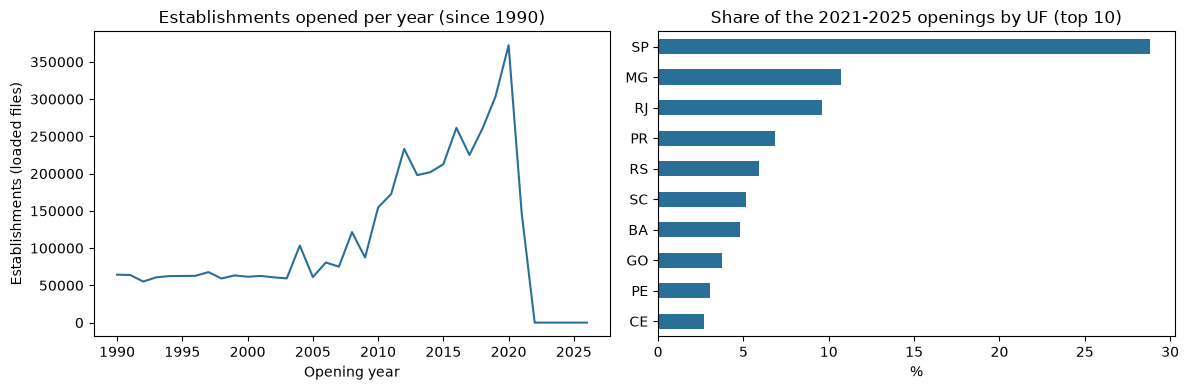

,cnae_fiscal_principal,cnae_descricao,estabelecimentos_2021_2025,share_pct
0,4781400,Comércio varejista de artigos do vestuário e a...,7370,5.0
1,7319002,Promoção de vendas,6483,4.4
2,9602501,"Cabeleireiros, manicure e pedicure",4914,3.3
3,4399103,Obras de alvenaria,4800,3.3
4,5620104,Fornecimento de alimentos preparados preponder...,4458,3.0
5,8219999,Preparação de documentos e serviços especializ...,4219,2.9
6,5611201,Restaurantes e similares,3850,2.6
7,5611203,"Lanchonetes, casas de chá, de sucos e similares",3303,2.2
8,4930201,"Transporte rodoviário de carga, exceto produto...",3293,2.2
9,4723700,Comércio varejista de bebidas,2799,1.9


In [2]:
anos = ano_uf.dropna(subset=["ano_inicio_atividade"]).astype({"ano_inicio_atividade": int})
por_ano = anos.groupby("ano_inicio_atividade")["estabelecimentos"].sum().loc[1990:]
recentes = anos[anos["ano_inicio_atividade"].between(r0, r1)]
uf_pct = recentes.groupby("uf")["estabelecimentos"].sum()
uf_pct = (uf_pct / uf_pct.sum() * 100).sort_values()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
por_ano.plot(ax=ax1, color="#2a6f97")
ax1.set(title="Establishments opened per year (since 1990)", xlabel="Opening year")
ax1.set_ylabel("Establishments (loaded files)")
uf_pct.tail(10).plot.barh(ax=ax2, color="#2a6f97")
ax2.set(title=f"Share of the {r0}-{r1} openings by UF (top 10)", xlabel="%", ylabel="")
fig.tight_layout()
plt.show()

col = f"estabelecimentos_{r0}_{r1}"
top_cnae = cnae.head(10).assign(share_pct=cnae[col] / recentes["estabelecimentos"].sum() * 100)
top_cnae[["cnae_fiscal_principal", "cnae_descricao", col, "share_pct"]]

**Conclusion.** Openings in this file grow through the 2010s and peak in **2020
(372,352 establishments) and 2019 (303,557)**, with 2016 and 2018 above 260,000; the file has
almost no openings after 2021 (sample bias above), so it cannot show the post-2021 trend. In
2021-2025 the openings concentrate in the South-East and South: **SP 28.8%, MG 10.7%, RJ 9.6%,
PR 6.8%, RS 5.9%, SC 5.1%**, close to the states' share of the economy. The leading main CNAEs
among those openings are small retail and personal services: **clothing retail (7,370),
sales promotion (6,483), hairdressers and beauty (4,914), masonry works (4,800) and prepared
food supply (4,458)** — a profile typical of micro-entrepreneurs.

## 2. How are active companies distributed by size (porte) and region?

Sources: `gold_distribuicao_porte` (companies by `porte_empresa`; `empresas_ativas` = companies
with at least one active establishment in the loaded files) and `gold_empresas_cnae_uf_ano`
rolled up to UF and then to the five IBGE regions (active establishments: a company with
branches in two regions counts in both, so regions are measured in establishments).

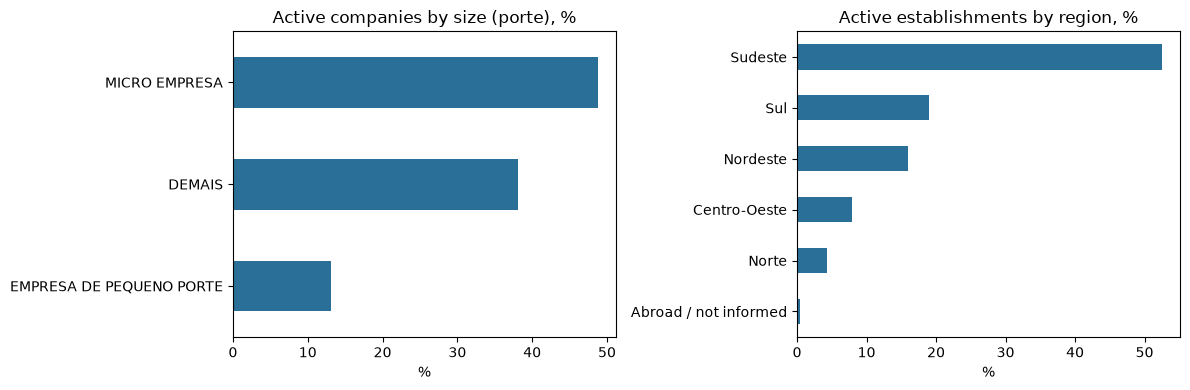

,empresas,empresas_ativas,share_of_active_pct,active_rate_pct
porte,,,,
MICRO EMPRESA,2164059,40236,48.8,1.9
EMPRESA DE PEQUENO PORTE,151105,10830,13.1,7.2
DEMAIS,2179696,31464,38.1,1.4


,estabelecimentos,estabelecimentos_ativos,share_of_active_pct,active_rate_pct
regiao,,,,
Sudeste,2393067,612591,52.5,25.6
Sul,876955,221112,18.9,25.2
Nordeste,834340,185987,15.9,22.3
Centro-Oeste,390945,91719,7.9,23.5
Norte,243397,50307,4.3,20.7
Abroad / not informed,14731,5681,0.5,38.6


In [3]:
REGIAO = {
    "Norte": "AC AM AP PA RO RR TO",
    "Nordeste": "AL BA CE MA PB PE PI RN SE",
    "Centro-Oeste": "DF GO MS MT",
    "Sudeste": "ES MG RJ SP",
    "Sul": "PR RS SC",
}
uf_regiao = {u: r for r, ufs in REGIAO.items() for u in ufs.split()}
regiao = (
    uf.assign(regiao=uf["uf"].map(uf_regiao).fillna("Abroad / not informed"))
    .groupby("regiao")[["estabelecimentos", "estabelecimentos_ativos"]]
    .sum()
    .assign(
        share_of_active_pct=lambda d: d.estabelecimentos_ativos
        / d.estabelecimentos_ativos.sum()
        * 100,
        active_rate_pct=lambda d: d.estabelecimentos_ativos / d.estabelecimentos * 100,
    )
    .sort_values("estabelecimentos_ativos")
)
porte_ativo = porte.assign(
    porte=porte["porte_descricao"].fillna("NULL / unknown"),
    share_of_active_pct=porte.empresas_ativas / porte.empresas_ativas.sum() * 100,
    active_rate_pct=porte.empresas_ativas / porte.empresas * 100,
).set_index("porte")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
porte_ativo["share_of_active_pct"].sort_values().plot.barh(ax=ax1, color="#2a6f97")
ax1.set(title="Active companies by size (porte), %", xlabel="%", ylabel="")
regiao["share_of_active_pct"].plot.barh(ax=ax2, color="#2a6f97")
ax2.set(title="Active establishments by region, %", xlabel="%", ylabel="")
fig.tight_layout()
plt.show()

display(porte_ativo[["empresas", "empresas_ativas", "share_of_active_pct", "active_rate_pct"]])
regiao.iloc[::-1]

**Conclusion.** By size, `Empresas1` splits into **micro companies 48.1%, "demais"
48.5% and small companies (EPP) 3.4%**; the `00` (not informed) code does not occur in this file.
Among companies with an active establishment in the loaded files, micro companies are the
largest group (**48.8%**), followed by "demais" (38.1%) and EPP (13.1%); EPPs show the highest
active rate (7.2% vs 1.9% and 1.4%), but the rates are low for every size because 90% of the
establishments of this run belong to companies outside `Empresas1`. By region, active
establishments concentrate in the **South-East (52.5%)**, then South (18.9%), North-East
(15.9%), Centre-West (7.9%) and North; the active rate is similar across regions (about 21-26%),
so the regional ranking reflects where companies are, not a regional difference in survival.

## 3. Which sectors have the most closed (baixadas) or unfit (inaptas) companies?

Source: `gold_situacao_setor` (establishments by `situacao_cadastral` x CNAE section/division of
the main CNAE). "Closed or unfit" = status `08` BAIXADA + `04` INAPTA. Two views: the volume
(which sectors concentrate them) and the rate within the sector (how many of the sector's
establishments are closed or unfit).

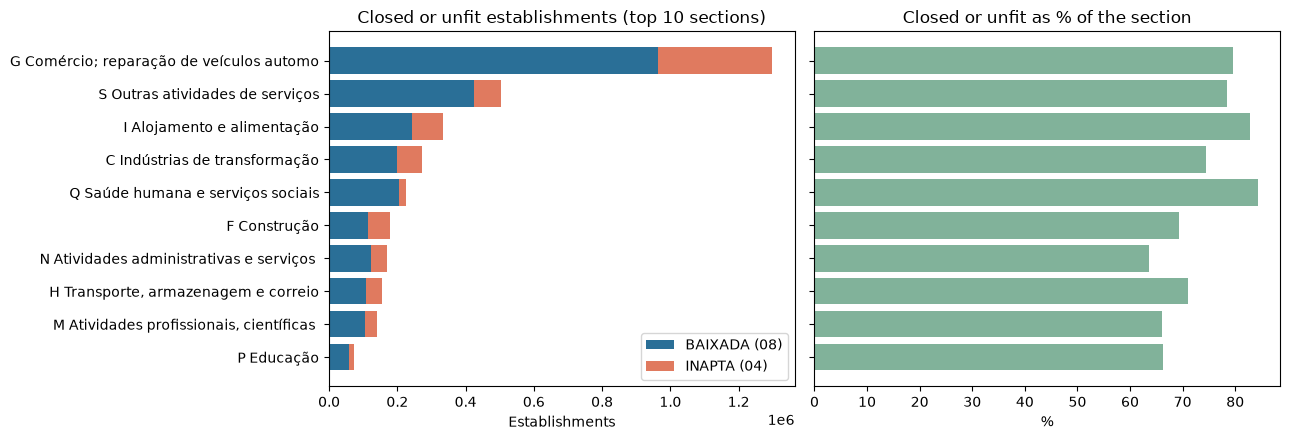

situacao_descricao,cnae_secao,cnae_secao_descricao,total,BAIXADA,INAPTA,share_of_closed_pct,closed_rate_pct
0,G,Comércio; reparação de veículos automotores e ...,1631743,962955,336165,36.6,79.6
1,S,Outras atividades de serviços,641627,424354,78835,14.2,78.4
2,I,Alojamento e alimentação,402496,243649,89673,9.4,82.8
3,C,Indústrias de transformação,368019,198618,75071,7.7,74.4
4,Q,Saúde humana e serviços sociais,266451,205873,18733,6.3,84.3
5,F,Construção,256363,112727,64865,5.0,69.3
6,N,Atividades administrativas e serviços compleme...,265250,124236,44315,4.7,63.5
7,H,"Transporte, armazenagem e correio",219313,107781,47777,4.4,70.9
8,M,"Atividades profissionais, científicas e técnicas",210579,105255,34020,3.9,66.1
9,P,Educação,110458,57100,15999,2.1,66.2


In [4]:
setor = setor.fillna(
    {"cnae_secao": "-", "cnae_secao_descricao": "CNAE not informed", "situacao_descricao": "OTHER"}
)
by = setor.pivot_table(
    index=["cnae_secao", "cnae_secao_descricao"],
    columns="situacao_descricao",
    values="estabelecimentos",
    aggfunc="sum",
    fill_value=0,
)
by = by.reindex(columns=sorted(set(by.columns) | {"ATIVA", "BAIXADA", "INAPTA"}), fill_value=0)
by["total"] = by.sum(axis=1)
by["baixadas_inaptas"] = by["BAIXADA"] + by["INAPTA"]
by["share_of_closed_pct"] = by.baixadas_inaptas / by.baixadas_inaptas.sum() * 100
by["closed_rate_pct"] = by.baixadas_inaptas / by.total * 100
by = by.sort_values("baixadas_inaptas", ascending=False)
top = by.head(10).iloc[::-1]
labels = [f"{s} {d[:38]}" for s, d in top.index]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
ax1.barh(labels, top["BAIXADA"], color="#2a6f97", label="BAIXADA (08)")
ax1.barh(labels, top["INAPTA"], left=top["BAIXADA"], color="#e07a5f", label="INAPTA (04)")
ax1.set(title="Closed or unfit establishments (top 10 sections)", xlabel="Establishments")
ax1.legend(loc="lower right")
ax2.barh(labels, top["closed_rate_pct"], color="#81b29a")
ax2.set(title="Closed or unfit as % of the section", xlabel="%")
fig.tight_layout()
plt.show()

cols = ["total", "BAIXADA", "INAPTA", "share_of_closed_pct", "closed_rate_pct"]
by[cols].head(10).reset_index()

**Conclusion.** In this (older) part of the registry **74.7% of the establishments are
closed or unfit** (2,700,643 BAIXADA + 851,567 INAPTA), against 1,167,397 active. In volume,
**trade and vehicle repair (section G) concentrates 36.6%** of the closed or unfit
establishments, followed by other services (S, 14.2%), accommodation and food (I, 9.4%),
manufacturing (C, 7.7%) and health (Q, 6.3%). As a rate within the sector (sections with at
least 5,000 establishments), the highest are **health and social services (84.3%),
accommodation and food (82.8%) and trade (79.6%)**, while public administration (21.2%),
agriculture (35.9%) and real estate (41.7%) are the most stable. Restaurants, retail and small
health practices are the sectors where companies most often stop operating.